# FraudRadar: train a fraud model on PaySim (Kaggle or Google Colab)

This notebook trains a LightGBM fraud model on the [PaySim](https://www.kaggle.com/datasets/ealaxi/paysim1)
dataset, from download to a saved model, and compares it with two baselines.

**How to run it on Kaggle** (the data is already there; CPU notebooks have several cores and plenty of RAM)
1. Create a new notebook at kaggle.com/code, then **File > Import Notebook** and upload this file.
2. In the right-hand panel choose **Add Input**, search for `paysim1` (*Synthetic Financial Datasets For Fraud Detection*, by ealaxi) and add it. No download or API key is needed.
3. Leave the accelerator on **None** (CPU); this model does not use a GPU. Switch **Internet** on in the settings only if the first cell says a library is missing.
4. Run from the top. Do a first run with `QUICK = True` (a few minutes), then set it to `False` for the real one.
5. Results are written to `/kaggle/working`. To keep them, choose **Save Version > Save & Run All (Commit)**. They then appear in the notebook's **Output** tab, where you can download them or turn them into a Kaggle Dataset.

**How to run it on Google Colab** instead: upload the notebook, run from the top, and give it your Kaggle token (`kaggle.json`, or `KAGGLE_USERNAME` and `KAGGLE_KEY` in Colab's Secrets) when asked. The last cell copies the results to your Google Drive (`SAVE_TO_DRIVE`) and downloads a zip; Colab's own disk is wiped when the session ends.

**The ideas this notebook is built around** (you should be able to explain each one):
- **Split by time, not at random.** A fraud model is used on tomorrow's payments, so it is tested on payments that come after the ones it learned from.
- **Features use only what was known before the payment.** The balance columns that describe the state *after* a payment are left out, because in PaySim they give the answer away.
- **Accuracy means nothing at 0.1% fraud.** The notebook reports average precision and the share of fraud caught at a fixed false-alarm rate.
- **Compare against baselines.** A model is only interesting if it beats a rule and a simple linear model.

In [1]:
# Install only what is missing. Kaggle and Colab both ship pandas, numpy, scikit-learn and matplotlib; Kaggle usually
# has LightGBM and SHAP too. Installing needs Internet to be switched on in Kaggle's notebook settings.
import importlib.util
import subprocess
import sys

missing = [pkg for pkg in ("lightgbm", "shap") if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("installed just now:", missing or "nothing (everything was already there)")

installed just now: nothing (everything was already there)


In [4]:
import gc
import hashlib
import json
import os
import shutil
import subprocess
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

IN_COLAB = "google.colab" in sys.modules
KAGGLE_INPUT = Path("/kaggle/input")    # datasets you attach with "Add Input"
KAGGLE_WORK = Path("/kaggle/working")   # whatever is saved here is kept by "Save Version"
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or KAGGLE_INPUT.exists()

# ---- settings you may want to change -----------------------------------------------------------------------
SEED = 7
QUICK = False            # True: a fast first run to check everything works. Set to False for the real run.
ABLATION = True         # also train on fewer feature groups to see what each group adds
RUN_LEAKAGE_DEMO = False  # optional: shows how the "after the payment" columns inflate the score
SAVE_TO_DRIVE = True    # Colab only: also copy the results to Google Drive (Colab's own disk is wiped at the end of a session)
DRIVE_DIR = "/content/drive/MyDrive/fraudradar"   # each run gets its own timestamped folder in here

TRAIN_END, VALID_END = 0.60, 0.80   # share of the timeline: train up to 60%, validate 60-80%, test the last 20%
FPR_TARGETS = (1e-3, 1e-4)          # false-alarm rates to report: 0.1% and 0.01% of honest payments

# Honest payments are down-sampled while training to save time, then weighted back up so scores stay comparable.
NEG_FRAC_TRAIN = 0.10 if QUICK else 0.25
NEG_FRAC_VALID = 0.10 if QUICK else 0.25   # same, only for the early-stopping set
MAX_ROUNDS = 300 if QUICK else 3000
LEARNING_RATE = 0.1 if QUICK else 0.05
# -------------------------------------------------------------------------------------------------------------

WORK = KAGGLE_WORK if IN_KAGGLE else (Path("/content/work") if IN_COLAB else Path("work"))
DATA_DIR, OUT_DIR = WORK / "data", WORK / "out"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
TYPES = ["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"]  # PaySim's five payment types
print("Kaggle:", IN_KAGGLE, "| Colab:", IN_COLAB, "| quick run:", QUICK)

Kaggle: True | Colab: False | quick run: False


## 1. Get the data

The cell below looks for a PaySim CSV in this order: the `PAYSIM_CSV` environment variable, then a dataset you
attached on Kaggle (`/kaggle/input`), then `work/data`, and only then (Colab or your own machine) downloads it with
the Kaggle API.

On Kaggle, just attach the dataset with **Add Input**. If you are on Colab and the download does not work, download
`PS_20174392719_1491204439457_log.csv` by hand from the dataset page, upload it to Colab (the folder icon on the left)
or to Google Drive, and set `PAYSIM_CSV` to its path.

In [5]:
def find_csv():
    override = os.environ.get("PAYSIM_CSV")
    if override and Path(override).exists():
        return Path(override)
    for folder in (KAGGLE_INPUT, DATA_DIR):
        if not folder.exists():
            continue
        found = sorted(folder.rglob("*.csv"), key=lambda p: p.stat().st_size, reverse=True)
        found = [p for p in found if "paysim" in str(p).lower() or p.name.startswith("PS_")] or found
        if found:
            return found[0]
    return None


def kaggle_credentials():
    """Make Kaggle credentials available: environment, then Colab secrets, then an uploaded kaggle.json."""
    if (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")) or (Path.home() / ".kaggle" / "kaggle.json").exists():
        return
    if not IN_COLAB:
        raise RuntimeError("Set KAGGLE_USERNAME and KAGGLE_KEY, or put kaggle.json in ~/.kaggle, or set PAYSIM_CSV.")
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        return
    except Exception:
        pass
    from google.colab import files
    print("Upload your kaggle.json (Kaggle > Settings > API > Create New Token).")
    files.upload()
    src = next(Path(".").glob("kaggle*.json"))
    target = Path.home() / ".kaggle"
    target.mkdir(exist_ok=True)
    shutil.copy(src, target / "kaggle.json")
    (target / "kaggle.json").chmod(0o600)


CSV = find_csv()
if CSV is None:
    if IN_KAGGLE:
        raise FileNotFoundError("PaySim is not attached to this notebook. In the right-hand panel choose Add Input, "
                                "search for paysim1, add it, then run this cell again.")
    if importlib.util.find_spec("kaggle") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)
    kaggle_credentials()
    subprocess.run(["kaggle", "datasets", "download", "-d", "ealaxi/paysim1", "-p", str(DATA_DIR), "--unzip"], check=True)
    CSV = find_csv()
assert CSV is not None, "No CSV found. Set PAYSIM_CSV to the path of the PaySim file."
print("Using", CSV, f"({CSV.stat().st_size / 1e6:.0f} MB)")

Using /kaggle/input/datasets/ealaxi/paysim1/PS_20174392719_1491204439457_log.csv (494 MB)


## 2. Load and look

Only columns known *before* the payment are loaded. `newbalanceOrig`, `newbalanceDest` and `isFlaggedFraud` are
deliberately left out: the first two describe the account after the payment (see the optional leakage demo below),
and the last one is the output of PaySim's own rule, which a model should not be allowed to copy.

In [6]:
usecols = ["step", "type", "amount", "nameOrig", "oldbalanceOrg", "nameDest", "oldbalanceDest", "isFraud"]
df = pd.read_csv(
    CSV,
    usecols=usecols,
    dtype={"step": "int16", "type": "category", "amount": "float32", "oldbalanceOrg": "float32",
           "oldbalanceDest": "float32", "isFraud": "int8"},
)
if not df["step"].is_monotonic_increasing:  # events must be in time order; the history features rely on it
    df = df.sort_values("step", kind="stable").reset_index(drop=True)

print(f"{len(df):,} payments over {df['step'].max()} hours (about {df['step'].max() / 24:.0f} days)")
print(f"fraud: {int(df['isFraud'].sum()):,} payments = {df['isFraud'].mean() * 100:.3f}%")
by_type = df.groupby("type", observed=True)["isFraud"].agg(payments="size", fraud="sum")
by_type["fraud_rate_%"] = (by_type["fraud"] / by_type["payments"] * 100).round(3)
by_type

6,362,620 payments over 743 hours (about 31 days)
fraud: 8,213 payments = 0.129%


,payments,fraud,fraud_rate_%
type,,,
CASH_IN,1399284,0,0.000
CASH_OUT,2237500,4116,0.184
DEBIT,41432,0,0.000
PAYMENT,2151495,0,0.000
TRANSFER,532909,4097,0.769


## 3. Features that only use the past

For each payment, every feature is computed from information that existed **before** it:

| Group | Features | Idea |
|---|---|---|
| **A. the payment itself** | type, amount, amount against the sender's balance, "drains the account", zero balances, merchant recipient, hour | Fraud in PaySim empties accounts into fresh, empty recipients |
| **B. history** | how many payments this sender made before, how many this recipient received before, how much | New or rarely used accounts are riskier |
| **C. chain** | has the *sender* just received money, how long ago, and how much of it is being passed on | A mule receives a transfer and cashes it out straight away |

Group C uses the same idea as FraudRadar's streaming features (an account that was just paid and now pays out).
Because payments are in time order, "earlier" simply means "a smaller row number".

In [7]:
A_FEATURES = ["type", "amount_log", "amount_to_oldbal", "drains_account", "orig_old_zero",
              "dest_old_zero", "dest_is_merchant", "hour"]
B_FEATURES = ["orig_prior_out", "dest_prior_in", "dest_prior_in_sum_log"]
C_FEATURES = ["recv_count", "steps_since_recv", "amount_to_last_recv"]
ALL_FEATURES = A_FEATURES + B_FEATURES + C_FEATURES


def build_features(frame):
    n = len(frame)
    step = frame["step"].to_numpy().astype("int32")
    amount = frame["amount"].to_numpy().astype("float64")
    old_orig = frame["oldbalanceOrg"].to_numpy().astype("float64")
    old_dest = frame["oldbalanceDest"].to_numpy().astype("float64")

    # Turn account names into integers: much faster and lighter than joining on strings.
    ids, _ = pd.factorize(pd.concat([frame["nameOrig"], frame["nameDest"]], ignore_index=True))
    orig_id, dest_id = ids[:n], ids[n:]
    event = np.arange(n)  # time order

    feats = pd.DataFrame({
        "type": frame["type"].astype(pd.CategoricalDtype(TYPES)).reset_index(drop=True),
        "amount_log": np.log1p(amount),
        "amount_to_oldbal": np.clip(amount / (old_orig + 1.0), 0, 100),
        "drains_account": ((old_orig > 0) & (amount >= old_orig - 0.01)).astype("int8"),
        "orig_old_zero": (old_orig == 0).astype("int8"),
        "dest_old_zero": (old_dest == 0).astype("int8"),
        "dest_is_merchant": (frame["nameDest"].str[0] == "M").to_numpy().astype("int8"),
        "hour": (step % 24).astype("int8"),
    })

    # B. history: cumcount counts how many earlier rows share the key, so it never includes the row itself.
    feats["orig_prior_out"] = pd.Series(orig_id).groupby(orig_id).cumcount().to_numpy()
    feats["dest_prior_in"] = pd.Series(dest_id).groupby(dest_id).cumcount().to_numpy()
    amt = pd.Series(amount)
    dest_in_before = amt.groupby(dest_id).cumsum().to_numpy() - amount  # exclusive running total
    feats["dest_prior_in_sum_log"] = np.log1p(dest_in_before)

    # C. chain: for each payment, the earlier payments that *arrived* at the sender's account.
    inbound = pd.DataFrame({"acct": dest_id, "event_in": event, "step_in": step, "amount_in": amount})
    senders = pd.DataFrame({"acct": orig_id, "event": event})
    senders = senders[senders["acct"].isin(np.unique(dest_id))]  # only senders that ever received anything
    m = senders.merge(inbound, on="acct")
    m = m[m["event_in"] < m["event"]].sort_values("event_in")
    g = m.groupby("event")
    recv = pd.DataFrame({"count": g.size(), "last_step": g["step_in"].last(), "last_amount": g["amount_in"].last()})
    recv = recv.reindex(event)
    feats["recv_count"] = recv["count"].fillna(0).to_numpy()
    feats["steps_since_recv"] = step - recv["last_step"].to_numpy()                     # missing if nothing arrived before
    feats["amount_to_last_recv"] = np.clip(amount / recv["last_amount"].to_numpy(), 0, 100)

    for col in feats.columns:  # smaller in memory
        if str(feats[col].dtype) == "float64":
            feats[col] = feats[col].astype("float32")
    return feats


t0 = time.time()
feats = build_features(df)
labels = df["isFraud"].to_numpy()
steps = df["step"].to_numpy()
print(f"{feats.shape[1]} features for {len(feats):,} payments in {time.time() - t0:.0f}s")
feats.describe().T[["mean", "min", "max"]].round(3)

14 features for 6,362,620 payments in 14s


,mean,min,max
amount_log,10.841,0.0,18.342
amount_to_oldbal,40.971,0.0,100.000
drains_account,0.312,0.0,1.000
orig_old_zero,0.330,0.0,1.000
dest_old_zero,0.425,0.0,1.000
dest_is_merchant,0.338,0.0,1.000
hour,15.321,0.0,23.000
orig_prior_out,0.001,0.0,2.000
dest_prior_in,5.096,0.0,112.000
dest_prior_in_sum_log,7.956,0.0,19.694


## 4. Split by time

Train on the earliest 60% of the timeline, choose settings on the next 20%, and keep the last 20% for the final
score. **Do not tune anything on the test part**; look at it once at the end.

In [8]:
t_train, t_valid = np.quantile(steps, [TRAIN_END, VALID_END])
is_train = steps <= t_train
is_valid = (steps > t_train) & (steps <= t_valid)
is_test = steps > t_valid

split = pd.DataFrame(
    {"hours": [f"1-{int(t_train)}", f"{int(t_train) + 1}-{int(t_valid)}", f"{int(t_valid) + 1}-{int(steps.max())}"],
     "payments": [int(m.sum()) for m in (is_train, is_valid, is_test)],
     "fraud": [int(labels[m].sum()) for m in (is_train, is_valid, is_test)]},
    index=["train", "validation", "test"])
split["fraud_rate_%"] = (split["fraud"] / split["payments"] * 100).round(3)
assert (split["fraud"] >= 20).all(), "Too few fraud cases in a split to measure anything reliably."
split

,hours,payments,fraud,fraud_rate_%
train,1-281,3820599,3193,0.084
validation,282-355,1293285,770,0.060
test,356-743,1248736,4250,0.340


## 4b. Reference statistics for the skew check

This writes `reference_stats.json`: for every feature, how its values were spread over the **training** part, for
all payments and for fraud alone. Once the model is serving, the live feature values are compared with it (the
training-serving skew check, `python -m fraudradar.skew`). A feature with 12 or fewer distinct values (flags, the
payment type) gets one bin per value; the others get ten bins cut at the deciles of the training part, assigned
with `np.searchsorted(edges, x, side="right")`. The serving side uses the same rules.

It needs only the data and the features, so you can stop the notebook after this cell if the skew check is all you
want from this run. Nothing here uses the model.

In [9]:
QUANTILES = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
MAX_DISCRETE = 12   # a feature with this many distinct values or fewer gets one bin per value


def reference_stats(frame, fraud_mask):
    """Spread of each feature over `frame`: shares per bin for all payments and for fraud, and a few quantiles."""
    stats = {}
    for col in ALL_FEATURES:
        values, fraud = frame[col], fraud_mask
        entry = {}
        if col == "type":
            codes = values.cat.codes.to_numpy()
            n_bins = len(TYPES)
            entry["kind"], entry["bins"] = "categorical", list(TYPES)
        else:
            x = values.to_numpy(dtype="float64")
            finite = x[~np.isnan(x)]
            distinct = np.unique(finite)
            if len(distinct) <= MAX_DISCRETE:   # flags and small counts: one bin per value, plus one for anything else
                at = np.minimum(np.searchsorted(distinct, x), len(distinct) - 1)
                codes = np.where(np.isnan(x), -1, np.where(distinct[at] == x, at, len(distinct)))
                n_bins = len(distinct) + 1
                entry["kind"], entry["values"] = "discrete", distinct.tolist()
            else:                               # everything else: ten bins cut at the deciles
                edges = np.unique(np.quantile(finite, np.linspace(0.1, 0.9, 9)))
                codes = np.where(np.isnan(x), -1, np.searchsorted(edges, x, side="right"))
                n_bins = len(edges) + 1
                entry["kind"], entry["edges"] = "numeric", edges.tolist()
        for name, mask in (("all", np.ones(len(codes), bool)), ("fraud", fraud)):
            c = codes[mask]
            present = c[c >= 0]
            entry[f"share_{name}"] = (np.bincount(present, minlength=n_bins) / max(1, len(present))).tolist()
            entry[f"missing_{name}"] = float((c < 0).mean()) if len(c) else 0.0
            if col != "type":
                xs = x[mask][~np.isnan(x[mask])]
                entry[f"quantiles_{name}"] = np.quantile(xs, QUANTILES).tolist() if len(xs) else []
        stats[col] = entry
    return stats


reference = {
    "split": "train",
    "rows": int(is_train.sum()),
    "fraud_rows": int(labels[is_train].sum()),
    "quantiles": QUANTILES,
    "features": reference_stats(feats[is_train].reset_index(drop=True), labels[is_train] == 1),
}
(OUT_DIR / "reference_stats.json").write_text(json.dumps(reference, indent=1))
print("reference statistics for", len(reference["features"]), "features saved")

reference statistics for 14 features saved


## 5. How we score

- **Average precision (AP)**: the area under the precision-recall curve. It is the headline number. A model that guesses randomly scores about the fraud rate (0.1%).
- **Recall at a fixed false-alarm rate**: set the alert threshold so that only 0.1% (or 0.01%) of *honest* payments are flagged, then see what share of the fraud is caught. This is how a fraud team thinks about it: "we can review this many alerts".
- The threshold is chosen on the **validation** part and then applied unchanged to the **test** part, so the test number is honest.

In [10]:
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve


def threshold_for_fpr(y_ref, p_ref, fpr):
    """Score above which only `fpr` of the honest payments in the reference part are flagged."""
    return float(np.quantile(p_ref[y_ref == 0], 1.0 - fpr))


def summarize(name, y, p, y_ref, p_ref):
    row = {"model": name, "AP": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p)}
    for fpr in FPR_TARGETS:
        thr = threshold_for_fpr(y_ref, p_ref, fpr)
        flagged = p > thr
        tp = int((flagged & (y == 1)).sum())
        fp = int((flagged & (y == 0)).sum())
        row[f"recall@{fpr:g}"] = tp / max(1, int((y == 1).sum()))
        row[f"precision@{fpr:g}"] = tp / max(1, tp + fp)
        row[f"false_alarm_rate@{fpr:g}"] = fp / max(1, int((y == 0).sum()))
    return row


results = []
curves = {}

## 6. Baseline 1: a rule

"Flag a transfer or cash-out that empties the sender's account." No learning at all. A model has to beat this.

In [11]:
y_test = labels[is_test]
rule = (feats.loc[is_test, "drains_account"].to_numpy() == 1) & feats.loc[is_test, "type"].isin(["TRANSFER", "CASH_OUT"]).to_numpy()
tp, fp = int((rule & (y_test == 1)).sum()), int((rule & (y_test == 0)).sum())
rule_row = {
    "model": "rule: drains account",
    "AP": np.nan, "ROC_AUC": np.nan,
    "recall@rule": tp / max(1, int(y_test.sum())),
    "precision@rule": tp / max(1, tp + fp),
    "false_alarm_rate@rule": fp / max(1, int((y_test == 0).sum())),
}
print({k: (round(v, 5) if isinstance(v, float) else v) for k, v in rule_row.items()})

{'model': 'rule: drains account', 'AP': nan, 'ROC_AUC': nan, 'recall@rule': 0.97224, 'precision@rule': 0.01748, 'false_alarm_rate@rule': 0.18662}


## 7. Baseline 2: logistic regression

A simple linear model on the same features. It cannot learn "this combination is suspicious", only "more of this is
more suspicious", so it shows how much the tree model's flexibility is worth.

In [12]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def linear_matrix(frame, cols):
    num = frame[[c for c in cols if c != "type"]].astype("float32")
    if "type" in cols:
        num = pd.concat([num, pd.get_dummies(frame["type"], dtype="float32")], axis=1)
    return num


rng = np.random.default_rng(SEED)
tr_idx = np.flatnonzero(is_train)
keep = (labels[tr_idx] == 1) | (rng.random(len(tr_idx)) < 0.05)   # all fraud, 5% of honest payments
tr_idx = tr_idx[keep]

logit = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      LogisticRegression(max_iter=300, class_weight="balanced"))
logit.fit(linear_matrix(feats.iloc[tr_idx], ALL_FEATURES), labels[tr_idx])
p_val_lr = logit.predict_proba(linear_matrix(feats[is_valid], ALL_FEATURES))[:, 1]
p_test_lr = logit.predict_proba(linear_matrix(feats[is_test], ALL_FEATURES))[:, 1]
results.append(summarize("logistic regression", labels[is_test], p_test_lr, labels[is_valid], p_val_lr))
curves["logistic regression"] = precision_recall_curve(labels[is_test], p_test_lr)[:2]
pd.DataFrame(results).round(4)

,model,AP,ROC_AUC,recall@0.001,precision@0.001,false_alarm_rate@0.001,recall@0.0001,precision@0.0001,false_alarm_rate@0.0001
0,logistic regression,0.6381,0.9961,0.6315,0.6616,0.0011,0.4113,0.8946,0.0002


## 8. LightGBM

A gradient-boosted tree model. Training stops by itself when the validation average precision stops improving.
Honest payments are down-sampled to save time and given a matching weight, so the model still sees the true
balance of fraud to honest.

In [13]:
import lightgbm as lgb


def sample_part(mask, neg_frac, seed):
    """All fraud rows plus a share of honest rows from `mask`, with weights that undo the down-sampling."""
    idx = np.flatnonzero(mask)
    r = np.random.default_rng(seed)
    idx = idx[(labels[idx] == 1) | (r.random(len(idx)) < neg_frac)]
    weights = np.where(labels[idx] == 1, 1.0, 1.0 / neg_frac)
    return idx, weights


def fit_lgbm(cols, verbose=100):
    tr, w_tr = sample_part(is_train, NEG_FRAC_TRAIN, SEED)
    va, w_va = sample_part(is_valid, NEG_FRAC_VALID, SEED + 1)
    model = lgb.LGBMClassifier(
        objective="binary", metric="average_precision", n_estimators=MAX_ROUNDS, learning_rate=LEARNING_RATE,
        num_leaves=63, min_child_samples=100, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbose=-1)
    model.fit(
        feats.iloc[tr][cols], labels[tr], sample_weight=w_tr,
        eval_set=[(feats.iloc[va][cols], labels[va])], eval_sample_weight=[w_va],
        callbacks=[lgb.early_stopping(100, first_metric_only=True, verbose=False), lgb.log_evaluation(verbose)])
    return model


def score_parts(model, cols):
    p_val = model.predict_proba(feats[is_valid][cols])[:, 1]
    p_test = model.predict_proba(feats[is_test][cols])[:, 1]
    return p_val, p_test


t0 = time.time()
model = fit_lgbm(ALL_FEATURES)
p_val, p_test = score_parts(model, ALL_FEATURES)
print(f"trained in {time.time() - t0:.0f}s, best round {model.best_iteration_}")
results.append(summarize("LightGBM (A+B+C)", labels[is_test], p_test, labels[is_valid], p_val))
curves["LightGBM (A+B+C)"] = precision_recall_curve(labels[is_test], p_test)[:2]
pd.DataFrame(results).round(4)

[100]	valid_0's average_precision: 0.999871
[200]	valid_0's average_precision: 1
trained in 17s, best round 113


,model,AP,ROC_AUC,recall@0.001,precision@0.001,false_alarm_rate@0.001,recall@0.0001,precision@0.0001,false_alarm_rate@0.0001
0,logistic regression,0.6381,0.9961,0.6315,0.6616,0.0011,0.4113,0.8946,0.0002
1,LightGBM (A+B+C),0.9995,1.0000,0.9998,0.8970,0.0004,0.9998,0.9849,0.0001


## 9. The result, and the precision-recall curve

Read the table from the left: `AP` first, then how much fraud is caught (`recall@...`) at each false-alarm budget,
and how many of the alerts are real (`precision@...`). The rule row is shown on its own because it is yes/no, not a score.

TEST part (threshold chosen on the validation part)
                         AP  ROC_AUC  recall@0.001  precision@0.001  false_alarm_rate@0.001  recall@0.0001  precision@0.0001  false_alarm_rate@0.0001
model                                                                                                                                                
logistic regression  0.6381   0.9961        0.6315           0.6616                  0.0011         0.4113            0.8946                   0.0002
LightGBM (A+B+C)     0.9995   1.0000        0.9998           0.8970                  0.0004         0.9998            0.9849                   0.0001

rule baseline on the test part: {'recall@rule': 0.97224, 'precision@rule': 0.01748, 'false_alarm_rate@rule': 0.18662}


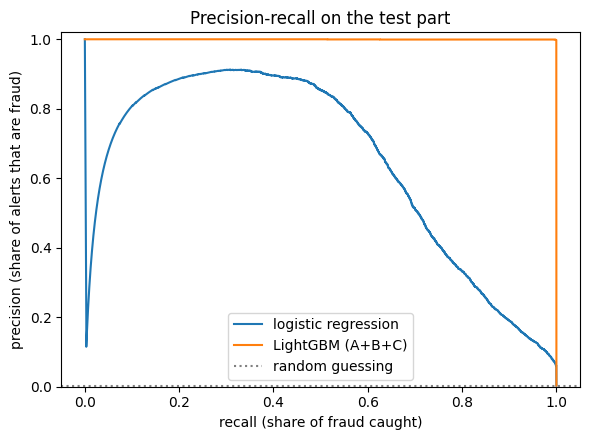

In [14]:
table = pd.DataFrame(results).set_index("model")
display_cols = [c for c in table.columns if c.startswith(("AP", "ROC", "recall@0", "precision@0", "false_alarm_rate@0"))]
print("TEST part (threshold chosen on the validation part)")
print(table[display_cols].round(4).to_string())
print("\nrule baseline on the test part:", {k: round(v, 5) for k, v in rule_row.items() if isinstance(v, float) and not np.isnan(v)})

fig, ax = plt.subplots(figsize=(6, 4.5))
for name, (precision, recall) in curves.items():
    ax.plot(recall, precision, label=name)
ax.axhline(labels[is_test].mean(), ls=":", c="grey", label="random guessing")
ax.set_xlabel("recall (share of fraud caught)")
ax.set_ylabel("precision (share of alerts that are fraud)")
ax.set_title("Precision-recall on the test part")
ax.set_ylim(0, 1.02)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "pr_curve.png", dpi=150)
plt.show()

## 10. What does each feature group add?

Train again with fewer feature groups. If the history and chain groups do not help, the model is just reading the
payment itself, and you should say so honestly.

In [15]:
if ABLATION:
    groups = {"A: the payment": A_FEATURES, "A+B: + history": A_FEATURES + B_FEATURES}
    for name, cols in groups.items():
        m = fit_lgbm(cols, verbose=0)
        pv, pt = score_parts(m, cols)
        results.append(summarize(f"LightGBM ({name})", labels[is_test], pt, labels[is_valid], pv))
        curves[f"LightGBM ({name})"] = precision_recall_curve(labels[is_test], pt)[:2]
        print("done", name, "best round", m.best_iteration_)
table = pd.DataFrame(results).set_index("model")
table[[c for c in table.columns if c.startswith(("AP", "recall@0", "precision@0"))]].round(4)

done A: the payment best round 85
done A+B: + history best round 55


,AP,recall@0.001,precision@0.001,recall@0.0001,precision@0.0001
model,,,,,
logistic regression,0.6381,0.6315,0.6616,0.4113,0.8946
LightGBM (A+B+C),0.9995,0.9998,0.8970,0.9998,0.9849
LightGBM (A: the payment),0.9995,0.9998,0.7101,0.9998,0.9736
LightGBM (A+B: + history),0.9985,0.9967,0.8818,0.9967,0.9647


## 11. Why did the model flag a payment?

FraudRadar shows a reason next to every blocked payment. With a tree model the reasons come from each feature's
contribution to that payment's score. `pred_contrib` is LightGBM's built-in version, fast enough to run per payment.
SHAP gives a fuller picture across many payments.

In [16]:
booster = model.booster_
X_test = feats[is_test][ALL_FEATURES]


def top_reasons(rows, k=3):
    contrib = booster.predict(rows, pred_contrib=True)          # last column is the base value
    names = list(rows.columns)
    out = []
    for j in range(len(rows)):
        order = np.argsort(-contrib[j, :-1])[:k]
        picked = []
        for i in order:
            if contrib[j, i] > 0:
                value = rows.iloc[j][names[i]]
                value = round(float(value), 3) if isinstance(value, (int, float, np.number)) else str(value)
                picked.append((names[i], value, round(float(contrib[j, i]), 2)))
        out.append(picked)
    return out


top = np.argsort(-p_test)[:5]
for j, reasons in zip(top, top_reasons(X_test.iloc[top])):
    print(f"score {p_test[j]:.3f} | really fraud: {bool(y_test[j])} | reasons: {reasons}")

score 1.000 | really fraud: True | reasons: [('amount_log', 14.169, 7.5), ('drains_account', 1.0, 6.42), ('amount_to_oldbal', 1.0, 5.33)]
score 1.000 | really fraud: True | reasons: [('amount_log', 14.128, 7.51), ('drains_account', 1.0, 6.38), ('amount_to_oldbal', 1.0, 5.33)]
score 1.000 | really fraud: True | reasons: [('amount_log', 14.292, 7.58), ('drains_account', 1.0, 6.5), ('amount_to_oldbal', 1.0, 5.43)]
score 1.000 | really fraud: True | reasons: [('amount_log', 14.281, 8.16), ('drains_account', 1.0, 6.29), ('amount_to_oldbal', 1.0, 5.42)]
score 1.000 | really fraud: True | reasons: [('amount_log', 13.896, 7.2), ('drains_account', 1.0, 6.37), ('amount_to_oldbal', 1.0, 5.35)]


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


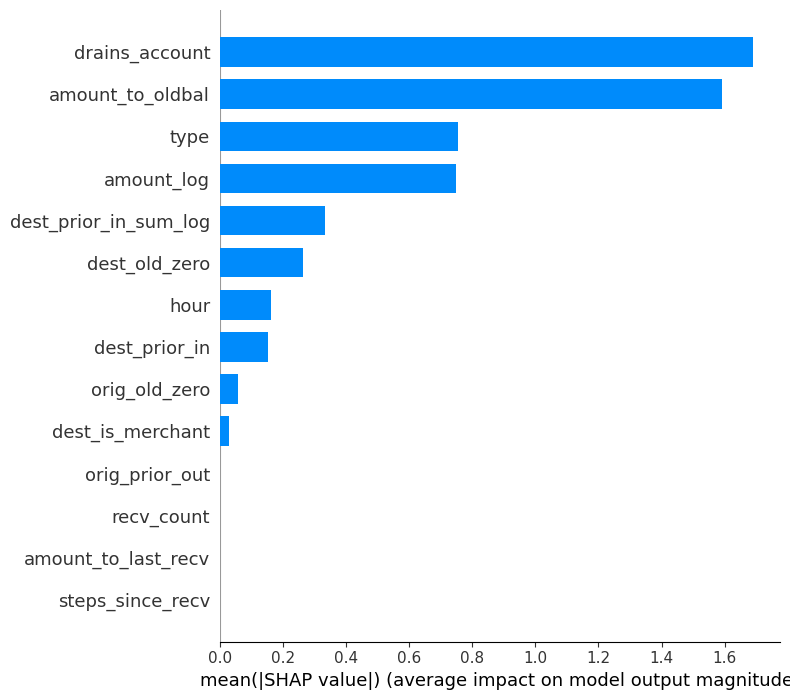

In [17]:
try:
    import shap
    rng = np.random.default_rng(SEED)
    fraud_rows = np.flatnonzero(y_test == 1)
    other_rows = rng.choice(np.flatnonzero(y_test == 0), size=min(4000, int((y_test == 0).sum())), replace=False)
    sample = X_test.iloc[np.concatenate([fraud_rows[:1000], other_rows])]
    values = shap.TreeExplainer(model).shap_values(sample)
    if isinstance(values, list):
        values = values[1]
    values = np.asarray(values)
    if values.ndim == 3:
        values = values[:, :, 1]
    shap.summary_plot(values, sample, plot_type="bar", show=False)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "shap_importance.png", dpi=150)
    plt.show()
except Exception as exc:  # plotting is a nicety; never lose a trained model over it
    print("SHAP plot skipped:", exc)

## 12. Will it be fast enough to serve?

FraudRadar decides in tens of milliseconds, and the whole path (broker, features, model) shares that budget. This
times one prediction on a single payment, the way the scorer would call it.

In [18]:
one = X_test.iloc[[0]]
timings = []
for _ in range(500):
    s = time.perf_counter()
    booster.predict(one)
    timings.append((time.perf_counter() - s) * 1000)
latency = {"p50_ms": round(float(np.percentile(timings, 50)), 3), "p99_ms": round(float(np.percentile(timings, 99)), 3)}
print("single-payment prediction:", latency)

single-payment prediction: {'p50_ms': 1.714, 'p99_ms': 3.331}


## 13. Optional: see what leakage looks like

Set `RUN_LEAKAGE_DEMO = True` at the top and re-run. This adds the balances recorded *after* each payment, as two
"does the arithmetic add up" errors. In PaySim those balances tend not to add up for fraudulent payments, so a
model can read the answer off them; compare the two AP numbers on your own run to see how much. Any jump is
**not a better model**: in real life the post-payment balance does not exist yet when you must decide.

In [19]:
if RUN_LEAKAGE_DEMO:
    extra = pd.read_csv(CSV, usecols=["step", "newbalanceOrig", "newbalanceDest"]).sort_values("step", kind="stable").reset_index(drop=True)
    leaky = feats.copy()
    leaky["error_orig"] = (extra["newbalanceOrig"].to_numpy() + df["amount"].to_numpy() - df["oldbalanceOrg"].to_numpy()).astype("float32")
    leaky["error_dest"] = (df["oldbalanceDest"].to_numpy() + df["amount"].to_numpy() - extra["newbalanceDest"].to_numpy()).astype("float32")
    saved, feats = feats, leaky
    try:
        leaky_cols = ALL_FEATURES + ["error_orig", "error_dest"]
        m = fit_lgbm(leaky_cols, verbose=0)
        pv, pt = score_parts(m, leaky_cols)
        row = summarize("LEAKY: LightGBM + after-payment balances", labels[is_test], pt, labels[is_valid], pv)
        print("honest model AP:", round(table.loc["LightGBM (A+B+C)", "AP"], 4), "| leaky model AP:", round(row["AP"], 4))
    finally:
        feats = saved

## 14. Save everything

This writes the model, the list of features in the right order (the scorer must build exactly these, in this order),
the thresholds, the metrics and the plots, and in Colab offers them as one zip download. The reference statistics
from section 4b are in the same folder.

In [20]:
def sha256_of(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        while block := fh.read(chunk):
            h.update(block)
    return h.hexdigest()


val_y, test_y = labels[is_valid], labels[is_test]
thresholds = {f"fpr_{fpr:g}": threshold_for_fpr(val_y, p_val, fpr) for fpr in FPR_TARGETS}
final_row = next(r for r in results if r["model"] == "LightGBM (A+B+C)")

booster.save_model(str(OUT_DIR / "lgbm_paysim.txt"))
pd.DataFrame(results).to_csv(OUT_DIR / "results.csv", index=False)
meta = {
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
    "dataset": "ealaxi/paysim1",
    "data_sha256": sha256_of(CSV),
    "rows": int(len(df)),
    "features": ALL_FEATURES,
    "type_categories": TYPES,
    "best_iteration": int(model.best_iteration_),
    "params": {k: v for k, v in model.get_params().items() if k in
               ("learning_rate", "num_leaves", "min_child_samples", "subsample", "colsample_bytree", "reg_lambda", "random_state")},
    "quick_run": QUICK,
    "split": {"train_end_hour": int(t_train), "valid_end_hour": int(t_valid)},
    "thresholds_chosen_on_validation": thresholds,
    "test_metrics": {k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in final_row.items() if k != "model"},
    "single_prediction_latency": latency,
    "versions": {"lightgbm": lgb.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
(OUT_DIR / "metadata.json").write_text(json.dumps(meta, indent=2, default=str))
print(json.dumps({k: meta[k] for k in ("best_iteration", "quick_run", "thresholds_chosen_on_validation", "single_prediction_latency")}, indent=2))

archive = shutil.make_archive(str(WORK / "fraud_model_paysim"), "zip", OUT_DIR)
print("saved:", archive)


def save_run_copy(root):
    """Copy this run's outputs into a new timestamped folder under `root`, so runs never overwrite each other."""
    run_dir = Path(root) / time.strftime("run_%Y%m%d_%H%M%S")
    run_dir.mkdir(parents=True, exist_ok=True)
    for item in list(OUT_DIR.iterdir()) + [Path(archive)]:
        shutil.copy(item, run_dir / item.name)
    return run_dir


if IN_COLAB and SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")          # asks you to allow access to your Drive
    print("also saved to Google Drive:", save_run_copy(DRIVE_DIR))

if IN_COLAB:
    from google.colab import files
    files.download(archive)

if IN_KAGGLE:
    print("Results are in", WORK, "- choose Save Version > Save & Run All (Commit) to keep them in the Output tab.")

{
  "best_iteration": 113,
  "quick_run": false,
  "thresholds_chosen_on_validation": {
    "fpr_0.001": 0.004236514046430132,
    "fpr_0.0001": 0.0063785377398281875
  },
  "single_prediction_latency": {
    "p50_ms": 1.714,
    "p99_ms": 3.331
  }
}
saved: /kaggle/working/fraud_model_paysim.zip
Results are in /kaggle/working - choose Save Version > Save & Run All (Commit) to keep them in the Output tab.


In [21]:
import os
from IPython.display import FileLink

os.chdir("/kaggle/working")
FileLink("out/reference_stats.json")

/kaggle/working/out/reference_stats.json

In [22]:
print(open("/kaggle/working/out/reference_stats.json").read())

{
 "split": "train",
 "rows": 3820599,
 "fraud_rows": 3193,
 "quantiles": [
  0.01,
  0.05,
  0.25,
  0.5,
  0.75,
  0.95,
  0.99
 ],
 "features": {
  "type": {
   "kind": "categorical",
   "bins": [
    "CASH_IN",
    "CASH_OUT",
    "DEBIT",
    "PAYMENT",
    "TRANSFER"
   ],
   "share_all": [
    0.21908711173300313,
    0.355273610237557,
    0.006147988836305511,
    0.336899789797359,
    0.08259149939577537
   ],
   "missing_all": 0.0,
   "share_fraud": [
    0.0,
    0.5029752583777012,
    0.0,
    0.0,
    0.49702474162229876
   ],
   "missing_fraud": 0.0
  },
  "amount_log": {
   "kind": "numeric",
   "edges": [
    8.339118385314942,
    9.116679763793947,
    9.719501304626466,
    10.461953353881837,
    11.223092079162598,
    11.714639663696289,
    12.079351043701172,
    12.40992774963379,
    12.79710159301758
   ],
   "share_all": [
    0.10000002617390624,
    0.10000002617390624,
    0.10000002617390624,
    0.10000002617390624,
    0.09999976443484386,
    0.099